# 03 — Data Cleaning & Train/Validation/Test Split
**Event Recommendation System** · Stage 4

Fix every data-quality problem found in notebook 01, then split the data **by time** so that no model can see the future.

### Setup (run this first)
- **In Google Colab** this cell downloads the project from GitHub (data + `src/` code) and moves into it.
- **On your own computer** it just moves from `notebooks/` to the project root.

`sys.path.insert(0, "src")` lets us `import recsys` - the small package that holds the reusable code (cleaning, models, metrics). Notebooks *explain* the code; `src/recsys` *stores* it so every notebook uses exactly the same implementation.

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/Abdelrahman2115/recommender-system.git"

if "google.colab" in sys.modules:                       # running inside Google Colab
    if not os.path.exists("/content/recommender-system"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/recommender-system"], check=True)
    os.chdir("/content/recommender-system")
elif os.path.basename(os.getcwd()) == "notebooks":      # running locally from the notebooks folder
    os.chdir("..")

sys.path.insert(0, "src")                               # make `import recsys` work
print("Project root:", os.getcwd())

Project root: /home/claude/recommender-system


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from recsys.plotting import set_style, MAIN, TEXT
set_style()

# Parse the date columns while reading (they were plain text in notebook 01)
users = pd.read_csv("data/raw/users.csv", parse_dates=["signup_date"])
events = pd.read_csv("data/raw/events.csv", parse_dates=["start_datetime"])
interactions = pd.read_csv("data/raw/interactions.csv", parse_dates=["timestamp"])
print(users.dtypes["signup_date"], events.dtypes["start_datetime"], interactions.dtypes["timestamp"])

datetime64[us] datetime64[us] datetime64[us]


## 1. Clean users

**City spelling.** `str.strip()` removes leading/trailing spaces and `str.title()` makes "CAIRO" and "cairo" become "Cairo".

**Ages.** Values below 13 or above 90 are impossible for this platform, so we treat them as missing. Then we fill missing ages with the **median** — the median is not pulled up by extreme values like 999 the way the mean is. (Age is not used by the models — EDA showed no signal — but a clean table is still good practice.)

In [3]:
users_clean = users.copy()                                  # never modify the raw data in place
users_clean["city"] = users_clean["city"].str.strip().str.title()

bad_age = (users_clean["age"] < 13) | (users_clean["age"] > 90)
print("impossible ages:", sorted(users_clean.loc[bad_age, "age"].astype(int)))
users_clean.loc[bad_age, "age"] = np.nan
print("missing ages before filling:", users_clean["age"].isna().sum())

users_clean["age"] = users_clean["age"].fillna(users_clean["age"].median()).astype(int)
users_clean["interests"] = users_clean["interests"].fillna("")

print("\ncities after cleaning:")
print(users_clean["city"].value_counts().to_string())

impossible ages: [0, 1, 3, 7, 120, 150, 210, 999]
missing ages before filling: 68

cities after cleaning:
city
Cairo         788
Giza          391
Alexandria    353
Mansoura      173
Tanta         111
Hurghada      103
Luxor          81


## 2. Clean events
- **Missing description → use the title.** The title still contains the event's main keyword, so the event keeps a useful text vector instead of an empty one.
- **Missing price → median price of the same category.** `groupby(...).transform("median")` returns, for every row, the median of *its own* category, so a missing tech-event price is filled with a typical tech price, not a typical concert price.

In [4]:
events_clean = events.copy()
events_clean["description"] = events_clean["description"].fillna(events_clean["title"])
events_clean["price"] = events_clean["price"].fillna(
    events_clean.groupby("category")["price"].transform("median"))
events_clean["tags"] = events_clean["tags"].fillna("")
print(events_clean[["description", "price"]].isna().sum())

description    0
price          0
dtype: int64


## 3. Clean interactions
1. `drop_duplicates()` removes the 500 rows that were logged twice.
2. Keep only rows whose user and event exist (none fail here, but the check protects against future data).
3. Business rule: only attended events may carry a rating; ratings must be between 1 and 5.
4. Keep **one row per (user, event)**, the latest one — a pair should be counted once.
5. Add `weight`, the strength of the implicit signal: view = 1, interested = 2, going = 3, attended = 4.

In [5]:
ENGAGEMENT_WEIGHT = {"view": 1, "interested": 2, "going": 3, "attended": 4}

inter = interactions.drop_duplicates().copy()
print("after removing duplicates:", len(inter))

inter = inter[inter["user_id"].isin(users_clean["user_id"]) & inter["event_id"].isin(events_clean["event_id"])]
inter.loc[inter["interaction_type"] != "attended", "rating"] = np.nan
inter = inter[inter["rating"].isna() | inter["rating"].between(1, 5)]
inter = inter.sort_values("timestamp").drop_duplicates(["user_id", "event_id"], keep="last")
inter["weight"] = inter["interaction_type"].map(ENGAGEMENT_WEIGHT)
inter = inter.reset_index(drop=True)
print("final interactions:", len(inter))
inter.head()

after removing duplicates: 50018
final interactions: 50018


,user_id,event_id,timestamp,interaction_type,rating,weight
0,312,226,2024-01-19 23:58:00,view,NaN,1
1,511,242,2024-01-21 09:08:00,view,NaN,1
2,470,72,2024-01-26 08:22:00,view,NaN,1
3,1276,170,2024-01-26 11:03:00,view,NaN,1
4,470,614,2024-01-26 18:02:00,going,NaN,3


### 3.1 Check: our step-by-step cleaning = the project's `recsys.data.load_clean()`
Later notebooks call `load_clean()` instead of repeating these cells. This assertion proves both give **identical** tables, so the explanation above is exactly what the pipeline runs.

In [6]:
from recsys.data import load_clean

u_ref, e_ref, i_ref = load_clean()
pd.testing.assert_frame_equal(users_clean, u_ref)
pd.testing.assert_frame_equal(events_clean, e_ref)
pd.testing.assert_frame_equal(inter, i_ref)
print("identical ✔")

identical ✔


## 4. Splitting the data: why *time*?

A recommender is used like this: *today*, using everything we know so far, recommend events for the *coming weeks*. The evaluation must copy that situation.

| Split method | Problem |
|---|---|
| Random 80/20 split | Training data would contain interactions from *after* test interactions → the model "sees the future" (**data leakage**), scores look better than reality. |
| Per-user "last 20%" split | Better, but user A's training data can still include other users' behaviour from after user A's test period (e.g. an event's later popularity). |
| **Global time split (ours)** | One cut-off date for everyone. Everything before it is known; everything after it is the future. No leakage. |

Our periods:
- **Train:** up to 1 Jul 2025 — used to fit models.
- **Validation:** 1 Jul → 1 Sep 2025 — used to choose hyperparameters (never for final scores).
- **Test:** 1 Sep → 31 Dec 2025 — touched **once**, at the very end. For the final run, models are re-trained on train + validation (all data before 1 Sep).

In [7]:
from recsys.data import temporal_split, TRAIN_END, VAL_END

train, val, test = temporal_split(inter)
summary = pd.DataFrame({
    "from": [inter["timestamp"].min(), TRAIN_END, VAL_END],
    "to": [TRAIN_END, VAL_END, inter["timestamp"].max()],
    "interactions": [len(train), len(val), len(test)],
    "ratings": [train["rating"].notna().sum(), val["rating"].notna().sum(), test["rating"].notna().sum()],
    "users": [train["user_id"].nunique(), val["user_id"].nunique(), test["user_id"].nunique()],
}, index=["train", "validation", "test"])
summary["share"] = (summary["interactions"] / len(inter)).map("{:.0%}".format)
summary

,from,to,interactions,ratings,users,share
train,2024-01-19 23:58:00,2025-07-01,23762,5056,1737,48%
validation,2025-07-01 00:00:00,2025-09-01,9386,1858,1774,19%
test,2025-09-01 00:00:00,2025-12-31,16870,3852,1900,34%


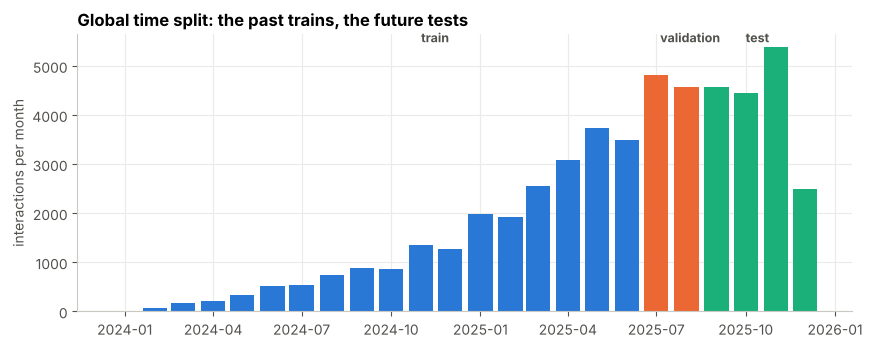

In [8]:
monthly = inter.set_index("timestamp").resample("MS").size()
colors = np.where(monthly.index < TRAIN_END, MAIN, np.where(monthly.index < VAL_END, "#eb6834", "#1baf7a"))

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(monthly.index, monthly.values, width=25, color=colors)
for label, x, c in [("train", pd.Timestamp("2024-11-01"), MAIN), ("validation", pd.Timestamp("2025-07-05"), "#eb6834"),
                    ("test", pd.Timestamp("2025-10-01"), "#1baf7a")]:
    ax.text(x, monthly.max() * 1.02, label, color=TEXT, fontsize=9, fontweight="bold")
ax.set_ylabel("interactions per month")
ax.set_title("Global time split: the past trains, the future tests")
plt.show()

## 5. What the models will face: cold start
At each cut-off we will recommend **events that take place in the next period**. How many of those events already have history?

In [9]:
def cold_start_report(history, future, start, end):
    """Share of the future's going/attended events (and users) that the history already knows."""
    cands = events_clean.loc[(events_clean["start_datetime"] > start) & (events_clean["start_datetime"] <= end), "event_id"]
    pos = future[future["interaction_type"].isin(["going", "attended"]) & future["event_id"].isin(cands)]
    ev_hist = history.groupby("event_id").size()
    n_hist = pos["event_id"].map(ev_hist).fillna(0)
    return pd.Series({
        "candidate events": len(cands),
        "relevant (user, event) pairs": len(pos),
        "relevant events with 0 past interactions": f"{(n_hist == 0).mean():.0%}",
        "relevant events with >=5 past interactions": f"{(n_hist >= 5).mean():.0%}",
        "users with past interactions": f"{pos['user_id'].isin(history['user_id']).mean():.0%}",
    })

pd.DataFrame({
    "validation (cut-off 1 Jul)": cold_start_report(train, val, TRAIN_END, VAL_END),
    "test (cut-off 1 Sep)": cold_start_report(pd.concat([train, val]), test, VAL_END, test["timestamp"].max()),
})

,validation (cut-off 1 Jul),test (cut-off 1 Sep)
candidate events,75,135
"relevant (user, event) pairs",2180,4695
relevant events with 0 past interactions,65%,81%
relevant events with >=5 past interactions,32%,19%
users with past interactions,84%,99%


**Takeaway:** most users (84% at the validation cut-off, 99% at the test cut-off) already have history, but **most of the events we must recommend have no history at all** (65% and 81%) at the moment of recommendation. This is the realistic situation for events, and it is why the final system is a **hybrid**: collaborative filtering for the events it knows, content for the new ones.

> We do not save the split to disk: `load_clean()` + `temporal_split()` take under a second and are deterministic, so every notebook recreates exactly the same split.

### Interview questions for this stage
- *What is data leakage?* — When information that would not be available at prediction time gets into training (e.g. future interactions). It makes offline scores look better than the model will perform for real.
- *Why a validation set as well as a test set?* — If we tune hyperparameters on the test set, we indirectly fit the test set and its score becomes optimistic. Validation is for choices; test is for the final, honest number.
- *Why fill missing price with the category median?* — A median is robust to extreme prices, and the category median is closer to the real value than a global median.

**Next:** `04_feature_engineering.ipynb`.